# 🌳 1.3 užduotis (b): Bank Marketing – Decision Forests (YDF / TF-DF)

Perdarytas dėstytojo notebook'as **„AdventureWorks DW using TensorFlow Decision Forests“** su kitais verslo duomenimis.

**Duomenys:** [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing) (taip pat [Kaggle](https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing)), licencija CC BY 4.0.
Portugalijos banko tiesioginės rinkodaros kampanija: banko darbuotojai skambino klientams ir siūlė terminuotą indėlį.
45 211 klientų, 16 požymių, tikslas `y` – ar klientas sutiko (*yes*/*no*). Kopija saugoma [`data/bank_marketing/`](https://github.com/edvakasas/Tensorflow/tree/main/data/bank_marketing).

Tai tiesioginis vTargetMail analogas: ten – „ar klientas pirks dviratį?“, čia – „ar klientas sutiks su indėliu?“.

*[Edvin Gladkich, Nojus Sadaunykas]*

## Kaip veikia originalus notebook'as (AdventureWorksDW_Decision Forests)

| Žingsnis | Ką daro originalas | Kodėl |
|---|---|---|
| 1. Duomenys | Įkelia tą patį `vTargetMail.csv`; jei yra `july4.csv`, naudoja jį (alternatyvūs duomenys). | Galimybė tą patį kodą paleisti su kitais duomenimis. |
| 2. Valymas | Kaip NN notebook'e: pašalinami ID ir asmens duomenys, `BikeBuyer` → `target`. | |
| 3. Aibės | 90:10 train / test (be validavimo aibės). | Atsitiktiniam miškui validavimo aibė nebūtina – jis vertinamas **out-of-bag** (OOB) pavyzdžiais. |
| 4. `pd_dataframe_to_tf_dataset` | Pandas lentelę tiesiai paverčia TF duomenų rinkiniu. | **Jokio kodavimo ar normalizavimo nereikia**: sprendimų medžiai patys apdoroja kategorinius ir skaitinius požymius. Tai didžiausias skirtumas nuo NN. |
| 5. Modelis | `RandomForestModel(num_trees=10, max_depth=15)`. | Atsitiktinis miškas – daug medžių, kiekvienas mokomas su atsitiktine duomenų ir požymių imtimi; galutinis atsakymas – balsavimas. |
| 6. Įvertinimas | `evaluate` testavimo aibėje (accuracy); OOB accuracy ir logloss priklausomai nuo medžių skaičiaus. | Matyti, kiek medžių pakanka, kad kokybė nustotų gerėti. |
| 7. Aiškinamumas | `plot_model_in_colab` nubraižo vieną medį; `dtreeviz` – vizualiai parodo kelią per medį konkrečiam klientui. | Medžiai, kitaip nei neuroninis tinklas, yra aiškinami: matyti, pagal kokias taisykles priimtas sprendimas. |
| 8. Naudojimas | `save`, įkėlimas per `TFSMLayer`, prognozė naujam klientui. | |

## Svarbu: TF-DF → YDF
Originalo pirma eilutė `pip install tensorflow_decision_forests` dabartiniame Colab **nebeveikia**: naujausia TF-DF versija reikalauja `tensorflow==2.15`, o Colab jau naudoja TensorFlow 2.20+ ir naujesnį Python.
TF-DF yra palaikymo režime, o Google rekomenduoja jo įpėdinį – **[YDF (Yggdrasil Decision Forests)](https://ydf.readthedocs.io/)**. Tai ta pati C++ biblioteka, kurią TF-DF naudojo „po gaubtu“, tik be TensorFlow priklausomybės, todėl algoritmai, hiperparametrai ir rezultatai tie patys. Modelį prireikus galima eksportuoti į TensorFlow SavedModel (`model.to_tensorflow_saved_model`).

| Originalas (TF-DF) | Mūsų versija (YDF) |
|---|---|
| `tfdf.keras.pd_dataframe_to_tf_dataset(train, label="target")` | nereikia – YDF priima pandas lentelę tiesiogiai |
| `tfdf.keras.RandomForestModel(...)` + `fit` | `ydf.RandomForestLearner(label="target", ...).train(train)` |
| `make_inspector().training_logs()` | `model.training_logs()` |
| `tfdf.model_plotter.plot_model_in_colab` | `model.plot_tree` |
| `save` + `TFSMLayer` | `model.save` + `ydf.load_model` |

## Ką keičiame su Bank Marketing duomenimis
- Pašaliname `duration` (nutekėjimas), naudojame **tą pačią testavimo aibę** kaip NN notebook'e, kad rezultatus būtų galima tiesiogiai palyginti.
- 300 medžių vietoj 10 (OOB kreivė parodo, kad 10 medžių nepakanka).
- Pridedame **požymių svarbą** (variable importance) ir palyginimą su **Gradient Boosted Trees**.
- Kadangi klasės nesubalansuotos, be accuracy matuojame AUC ir parodome, kaip **sprendimo slenkstis** keičia precision ir recall.
- `dtreeviz` praleidžiame (nesuderinamas su YDF) – medį braižome `plot_tree`.

In [1]:
#@title 🔗 SETUP: YDF (TensorFlow Decision Forests įpėdinis)
!pip install -q ydf
import ydf
print("ydf", ydf.__version__)

ydf 0.15.0


In [2]:
#@title 📥 STEP 1: Duomenų įkėlimas iš GitHub
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/edvakasas/Tensorflow/main/data/bank_marketing/bank-full.csv"
df_all_col = pd.read_csv(DATA_URL, sep=";")
print("The dataframe has {} rows and {} columns.".format(df_all_col.shape[0], df_all_col.shape[1]))
display(df_all_col.head())

The dataframe has 45211 rows and 17 columns.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


y
no     0.883
yes    0.117

Jei visada spėtume „no“, tikslumas būtų 88.3% – todėl vien accuracy čia nepakanka.


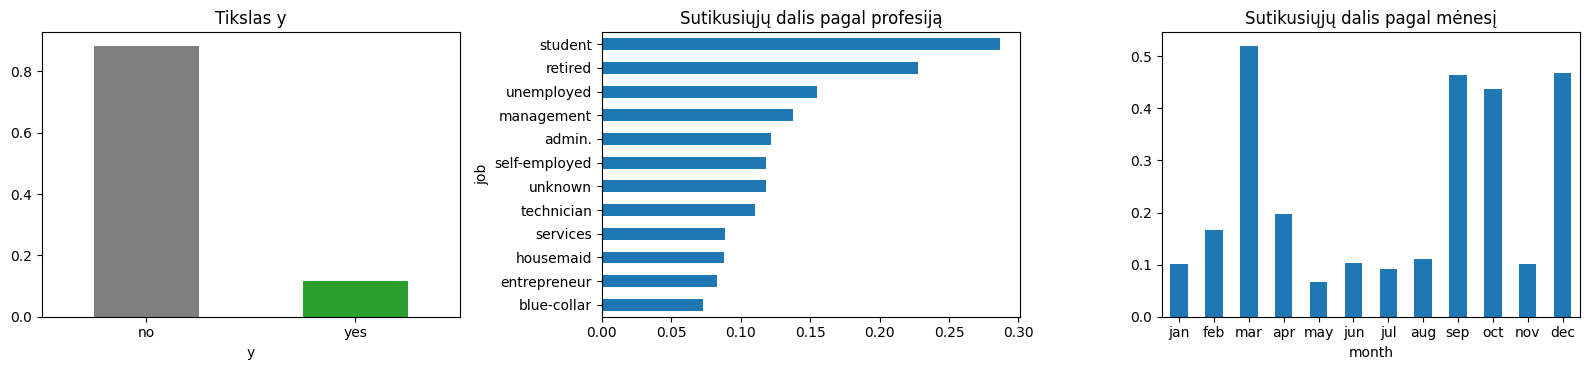

In [3]:
#@title 🔎 STEP 2: Tiriamoji analizė – tikslo pasiskirstymas
import matplotlib.pyplot as plt

share = df_all_col["y"].value_counts(normalize=True)
print(share.round(3).to_string())
print(f"\nJei visada spėtume „no“, tikslumas būtų {share['no']:.1%} – todėl vien accuracy čia nepakanka.")

yes_rate = lambda col: df_all_col.groupby(col)["y"].apply(lambda s: (s == "yes").mean())
months = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
share.plot.bar(ax=axes[0], title="Tikslas y", color=["tab:grey", "tab:green"], rot=0)
yes_rate("job").sort_values().plot.barh(ax=axes[1], title="Sutikusiųjų dalis pagal profesiją")
yes_rate("month").reindex(months).plot.bar(ax=axes[2], title="Sutikusiųjų dalis pagal mėnesį", rot=0)
plt.tight_layout()
plt.show()

In [4]:
#@title 🧹 STEP 3: Paruošimas – nutekėjimo pašalinimas ir tikslas
df = df_all_col.copy()

# duration – pokalbio trukmė. Ji žinoma tik PO skambučio, kai atsakymas jau aiškus,
# todėl modelis, išmokęs iš jos, realiai prognozuoti negalėtų (duomenų nutekėjimas).
df.drop(columns=["duration"], inplace=True)
df["target"] = (df.pop("y") == "yes").astype("int64")  # originale: BikeBuyer → target

CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
NUMERIC = ["age", "balance", "day", "campaign", "pdays", "previous"]
df[CATEGORICAL] = df[CATEGORICAL].astype(object)
df[NUMERIC] = df[NUMERIC].astype("float32")
print(df.iloc[0])

age                58.0
job          management
marital         married
education      tertiary
default              no
balance          2143.0
housing             yes
loan                 no
contact         unknown
day                 5.0
month               may
campaign            1.0
pdays              -1.0
previous            0.0
poutcome        unknown
target                0
Name: 0, dtype: object


In [5]:
#@title ✂️ STEP 4: Mokymo ir testavimo aibės (90:10, tas pats test kaip NN notebook'e)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
n = len(df)
train = df.iloc[: int(0.9 * n)]  # NN notebook'e tai train + validation
test = df.iloc[int(0.9 * n):]
print(len(train), "training examples")
print(len(test), "test examples")
# TF-DF reikėjo pd_dataframe_to_tf_dataset; YDF mokosi tiesiai iš pandas lentelės

40689 training examples
4522 test examples


## 5 žingsnis – atsitiktinis miškas

In [6]:
#@title 🌲 STEP 5: RandomForestLearner
model_1 = ydf.RandomForestLearner(label="target", num_trees=300, max_depth=16, random_seed=42,
                                  compute_oob_variable_importances=True).train(train)
evaluation = model_1.evaluate(test)
print(f"Test accuracy {evaluation.accuracy:.4f}, AUC {evaluation.characteristics[0].auc:.4f}")

Train model on 40689 examples
Model trained in 0:01:16.045242
Test accuracy 0.8927, AUC 0.7761


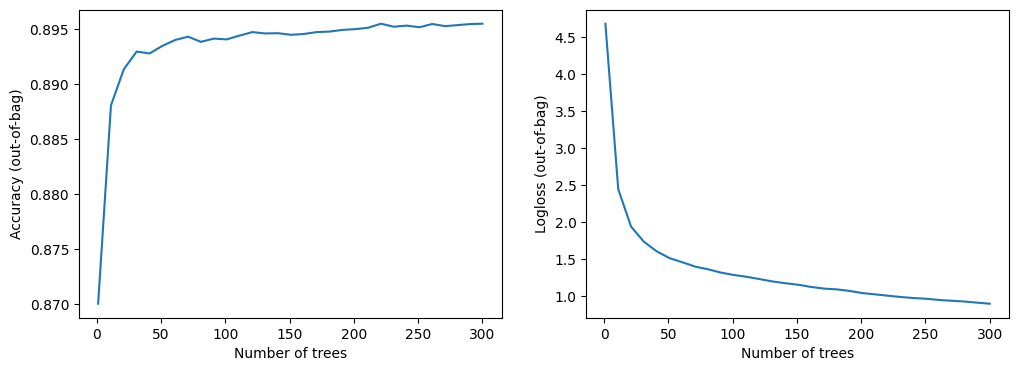

In [7]:
#@title 📈 STEP 6: OOB kokybė pagal medžių skaičių (kaip originale)
import matplotlib.pyplot as plt

logs = [log for log in model_1.training_logs() if log.evaluation.accuracy is not None]
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot([log.iteration for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel("Number of trees"); plt.ylabel("Accuracy (out-of-bag)")
plt.subplot(1, 2, 2)
plt.plot([log.iteration for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel("Number of trees"); plt.ylabel("Logloss (out-of-bag)")
plt.show()

## 7 žingsnis – aiškinamumas: vienas medis ir požymių svarba

In [8]:
#@title 🌳 STEP 7a: Pirmasis medis (pirmi 3 lygiai)
model_1.plot_tree(tree_idx=0, max_depth=3)

**Požymių svarba** `MEAN_DECREASE_IN_AUC`: kiek sumažėja modelio AUC (out-of-bag pavyzdžiuose), kai to požymio reikšmės atsitiktinai sumaišomos. Kuo didesnis sumažėjimas, tuo labiau modelis tuo požymiu remiasi.

Prieinami svarbos tipai: ['MEAN_DECREASE_IN_ACCURACY', 'SUM_SCORE', 'NUM_AS_ROOT', 'NUM_NODES', 'INV_MEAN_MIN_DEPTH', 'MEAN_DECREASE_IN_AUC_1_VS_OTHERS', 'MEAN_DECREASE_IN_PRAUC_1_VS_OTHERS', 'MEAN_DECREASE_IN_AP_1_VS_OTHERS']


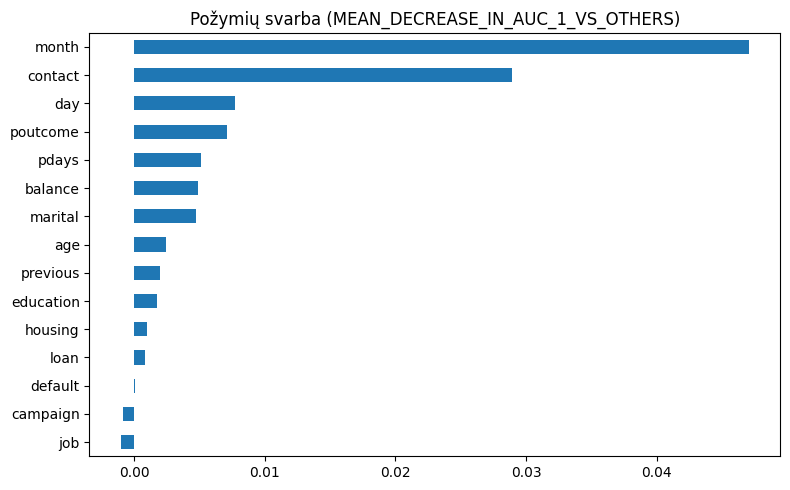

In [9]:
#@title 📊 STEP 7b: Požymių svarba
importances = model_1.variable_importances()
print("Prieinami svarbos tipai:", list(importances))
kind = "MEAN_DECREASE_IN_AUC_1_VS_OTHERS" if "MEAN_DECREASE_IN_AUC_1_VS_OTHERS" in importances else "SUM_SCORE"
imp = pd.Series({name: value for value, name in importances[kind]}).sort_values()
imp.plot.barh(figsize=(8, 5), title=f"Požymių svarba ({kind})")
plt.tight_layout()
plt.show()

## 8 žingsnis – palyginimas su Gradient Boosted Trees ir sprendimo slenksčiu
Gradient Boosted Trees medžius kuria nuosekliai: kiekvienas naujas medis taiso ankstesnių klaidas. Toliau lyginame abu modelius ir parodome, kaip slenkstis (nuo kurios tikimybės klientą laikome „yes“) keičia precision ir recall.

Train model on 40689 examples
Model trained in 0:00:03.619313


Accuracy    AUC  Precision  Recall
Modelis                Slenkstis                                    
Random Forest          0.50          0.893  0.776      0.638   0.181
                       0.25          0.887  0.776      0.519   0.424
Gradient Boosted Trees 0.50          0.894  0.802      0.617   0.226
                       0.25          0.883  0.802      0.499   0.466

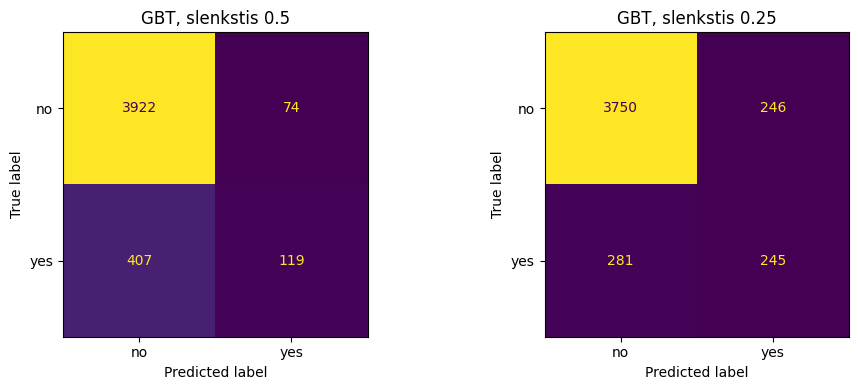

In [10]:
#@title ⚖️ STEP 8: RF vs GBT, slenksčio įtaka
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, ConfusionMatrixDisplay
import numpy as np

model_2 = ydf.GradientBoostedTreesLearner(label="target", random_seed=42).train(train)

y_test = test["target"].to_numpy()
probs = {"Random Forest": model_1.predict(test),  # tikimybė, kad target = 1
         "Gradient Boosted Trees": model_2.predict(test)}
rows = []
for name, p in probs.items():
    for threshold in (0.5, 0.25):
        pred = (p >= threshold).astype(int)
        rows.append({"Modelis": name, "Slenkstis": threshold, "Accuracy": accuracy_score(y_test, pred),
                     "AUC": roc_auc_score(y_test, p), "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred)})
results = pd.DataFrame(rows).set_index(["Modelis", "Slenkstis"]).round(3)
display(results)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, threshold in zip(axes, (0.5, 0.25)):
    ConfusionMatrixDisplay.from_predictions(y_test, (probs["Gradient Boosted Trees"] >= threshold).astype(int),
                                            display_labels=["no", "yes"], ax=ax, colorbar=False)
    ax.set_title(f"GBT, slenkstis {threshold}")
plt.tight_layout()
plt.show()

## 9 žingsnis – išsaugojimas ir prognozė naujiems klientams (kaip originale)

In [11]:
SAMPLES = {
    "Klientas A (anksčiau sutiko, skambinta spalį)": {
        "age": 35, "job": "management", "marital": "single", "education": "tertiary", "default": "no",
        "balance": 1500, "housing": "no", "loan": "no", "contact": "cellular", "day": 15, "month": "oct",
        "campaign": 1, "pdays": 180, "previous": 2, "poutcome": "success"},
    "Klientas B (pirmas kontaktas, skambinta gegužę, 5-as skambutis)": {
        "age": 45, "job": "blue-collar", "marital": "married", "education": "primary", "default": "no",
        "balance": 100, "housing": "yes", "loan": "yes", "contact": "unknown", "day": 20, "month": "may",
        "campaign": 5, "pdays": -1, "previous": 0, "poutcome": "unknown"},
}

#@title 💾 STEP 9: Išsaugojimas ir prognozė
model_1.save("bank_marketing_random_forest")
reloaded_model = ydf.load_model("bank_marketing_random_forest")

new_observation_df = pd.DataFrame(list(SAMPLES.values()))
new_observation_df[CATEGORICAL] = new_observation_df[CATEGORICAL].astype(object)
new_observation_df[NUMERIC] = new_observation_df[NUMERIC].astype("float32")
for name, rf, gbt in zip(SAMPLES, reloaded_model.predict(new_observation_df), model_2.predict(new_observation_df)):
    print(f"{name}: RF {100 * rf:.1f} %, GBT {100 * gbt:.1f} %")

Loading model from bank_marketing_random_forest
Klientas A (anksčiau sutiko, skambinta spalį): RF 78.3 %, GBT 74.8 %
Klientas B (pirmas kontaktas, skambinta gegužę, 5-as skambutis): RF 0.7 %, GBT 2.9 %


## Išvados
- Decision Forests nereikia jokio požymių kodavimo ar normalizavimo, todėl kodas daug trumpesnis nei NN versijoje.
- OOB kreivė rodo, kad tikslumas kyla maždaug iki 100 medžių, vėliau beveik nekinta – originalo 10 medžių šiems duomenims per mažai.
- Svarbiausi požymiai – **mėnuo** (`month`), **kontakto būdas** (`contact`), **diena** ir **ankstesnės kampanijos rezultatas** (`poutcome`). Kada ir kaip skambinama lemia daugiau nei kliento demografija (`job`, `campaign` beveik nesvarbūs) – tai tiesiogiai naudinga rinkodaros komandai.
- Slenkstis 0,5 duoda aukštą accuracy, bet žemą recall. GBT sumažinus slenkstį iki 0,25, recall padidėja nuo 0,23 iki 0,47, o precision sumažėja nuo 0,62 iki 0,50.

### Palyginimas su NN notebook'u (ta pati testavimo aibė, 4 522 klientai)

| Modelis | AUC | Accuracy (0,5) | Recall (0,5) |
|---|---|---|---|
| Visada „no“ | 0,500 | 0,884 | 0,000 |
| NN A | 0,798 | 0,890 | 0,173 |
| NN B (klasių svoriai) | 0,791 | 0,820 | 0,586 |
| Random Forest | 0,776 | 0,893 | 0,181 |
| **Gradient Boosted Trees** | **0,802** | 0,894 | 0,226 |

GBT pasiekė geriausią AUC be jokio duomenų paruošimo; NN jam beveik nenusileidžia. Didelis NN B recall gaunamas ne dėl geresnio modelio, o dėl klasių svorių, kurie pastumia tikimybes aukštyn – panašų efektą medžiams duoda mažesnis slenkstis. Dėl tos pačios priežasties NN B tikimybės nėra kalibruotos (klientui A – 94,9 %, kai RF/GBT duoda 75–78 %).